# Exploration - Crime recorded by the police and gendarmerie (SSMSI)

**@author: Alexis PERRIN**

**@group : DE1**

**Introduction**
This notebook is the exploration I did before building the Streamlit app.
The goal is to understand the dataset, clean it and check which questions we can answer.

**Questions**
- How has recorded crime evolved since 2016 ?
- Which types of crime are increasing or decreasing ?
- Which departments are the most affected ?

## 1. Load the data

In [1]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
path = glob.glob("../data/donnee-dep*.csv")[0] #the name of the file changes every year
print(path)

../data/donnee-dep-data.gouv-2025-geographie2026-produit-le2026-06-25.csv


In [3]:
df = pd.read_csv(path, sep=";", decimal=",", dtype={"Code_departement": str, "Code_region": str})

In [4]:
df.head()

,Code_departement,Code_region,annee,indicateur,unite_de_compte,nombre,taux_pour_mille,insee_pop,insee_pop_millesime,insee_log,insee_log_millesime
0,01,84,2016,Homicides,Victime,5,0.007832,638425,2016,308491,2016
1,02,32,2016,Homicides,Victime,10,0.018652,536136,2016,264180,2016
2,03,84,2016,Homicides,Victime,4,0.011786,339384,2016,206980,2016
3,04,93,2016,Homicides,Victime,2,0.012303,162565,2016,126760,2016
4,05,93,2016,Homicides,Victime,0,0.000000,141107,2016,134647,2016


In [5]:
df.tail()

,Code_departement,Code_region,annee,indicateur,unite_de_compte,nombre,taux_pour_mille,insee_pop,insee_pop_millesime,insee_log,insee_log_millesime
18175,971,01,2025,Escroqueries et fraudes aux moyens de paiement,Victime,1885,4.906810,384160,2023,237578,2022
18176,972,02,2025,Escroqueries et fraudes aux moyens de paiement,Victime,1350,3.743449,360630,2023,220301,2022
18177,973,03,2025,Escroqueries et fraudes aux moyens de paiement,Victime,697,2.370781,293996,2023,100424,2022
18178,974,04,2025,Escroqueries et fraudes aux moyens de paiement,Victime,2884,3.241619,889679,2023,400595,2022
18179,976,06,2025,Escroqueries et fraudes aux moyens de paiement,Victime,427,1.664600,256518,2017,73880,2017


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18180 entries, 0 to 18179
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Code_departement     18180 non-null  str    
 1   Code_region          18180 non-null  str    
 2   annee                18180 non-null  int64  
 3   indicateur           18180 non-null  str    
 4   unite_de_compte      18180 non-null  str    
 5   nombre               18180 non-null  int64  
 6   taux_pour_mille      18180 non-null  float64
 7   insee_pop            18180 non-null  int64  
 8   insee_pop_millesime  18180 non-null  int64  
 9   insee_log            18180 non-null  int64  
 10  insee_log_millesime  18180 non-null  int64  
dtypes: float64(1), int64(6), str(4)
memory usage: 2.2 MB


In [7]:
df.describe()

,annee,nombre,taux_pour_mille,insee_pop,insee_pop_millesime,insee_log,insee_log_millesime
count,18180.00000,18180.000000,18180.000000,1.818000e+04,18180.000000,1.818000e+04,18180.000000
mean,2020.50000,1813.366722,2.453351,6.690948e+05,2020.168317,3.653104e+05,2019.871287
std,2.87236,4204.858352,2.868400,5.130550e+05,2.489926,2.620848e+05,2.173998
min,2016.00000,0.000000,0.000000,7.642200e+04,2016.000000,6.039500e+04,2016.000000
25%,2018.00000,161.000000,0.437891,2.833720e+05,2018.000000,1.653150e+05,2018.000000
50%,2020.50000,705.000000,1.668044,5.284210e+05,2020.000000,2.954295e+05,2020.000000
75%,2023.00000,1897.000000,3.403202,8.529240e+05,2023.000000,4.867690e+05,2022.000000
max,2025.00000,162378.000000,74.986735,2.616909e+06,2023.000000,1.399122e+06,2022.000000


## 2. Data Exploration & Cleaning

In [8]:
df.columns = [c.lower() for c in df.columns]
df.columns

Index(['code_departement', 'code_region', 'annee', 'indicateur',
       'unite_de_compte', 'nombre', 'taux_pour_mille', 'insee_pop',
       'insee_pop_millesime', 'insee_log', 'insee_log_millesime'],
      dtype='str')

In [10]:
df["indicateur"].unique()

<ArrowStringArray>
[                                     'Homicides',
                          'Tentatives d'homicide',
            'Violences physiques intrafamiliales',
        'Violences physiques hors cadre familial',
                            'Violences sexuelles',
                                'Vols avec armes',
                        'Vols violents sans arme',
        'Vols sans violence contre des personnes',
                       'Cambriolages de logement',
                               'Vols de véhicule',
                        'Vols dans les véhicules',
               'Vols d'accessoires sur véhicules',
       'Destructions et dégradations volontaires',
                           'Usage de stupéfiants',
                     'Usage de stupéfiants (AFD)',
                'Usage de stupéfiants (hors AFD)',
                          'Trafic de stupéfiants',
 'Escroqueries et fraudes aux moyens de paiement']
Length: 18, dtype: str

In [34]:
df["code_departement"].unique()

<ArrowStringArray>
[ '01',  '02',  '03',  '04',  '05',  '06',  '07',  '08',  '09',  '10',
 ...
  '91',  '92',  '93',  '94',  '95', '971', '972', '973', '974', '976']
Length: 101, dtype: str

- Each row is one department, one year and one type of crime (indicateur)

In [11]:
df["unite_de_compte"].value_counts()

unite_de_compte
Victime             6060
Infraction          4040
Mis en cause        4040
Véhicule            3030
Victime entendue    1010
Name: count, dtype: int64

- The indicators don't have the same unit (victims, infractions, vehicles...) so we can not add them together.

In [12]:
df["annee"].unique()

array([2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025])

In [13]:
df["code_departement"].nunique()

101

- Now we look for missing values

In [14]:
missing = df.isnull().sum()
print(missing)

code_departement       0
code_region            0
annee                  0
indicateur             0
unite_de_compte        0
nombre                 0
taux_pour_mille        0
insee_pop              0
insee_pop_millesime    0
insee_log              0
insee_log_millesime    0
dtype: int64


- Now we check for duplicates

In [16]:
duplicate = df.duplicated().sum()
print(duplicate)
print(df.duplicated(subset=["code_departement", "annee", "indicateur"]).sum())

0
0


## 3. Feature Engineering

In [18]:
def get_period(year):
    if year < 2020:
        return 'Before Covid'
    elif year == 2020:
        return 'Covid'
    else:
        return 'After Covid'

df['periode'] = df['annee'].map(get_period)
df['periode'].value_counts()

periode
After Covid     9090
Before Covid    7272
Covid           1818
Name: count, dtype: int64

In [19]:
df['outre_mer'] = df['code_departement'].str.len() == 3
df['outre_mer'].value_counts()

outre_mer
False    17280
True       900
Name: count, dtype: int64

## 4. Data Visualization

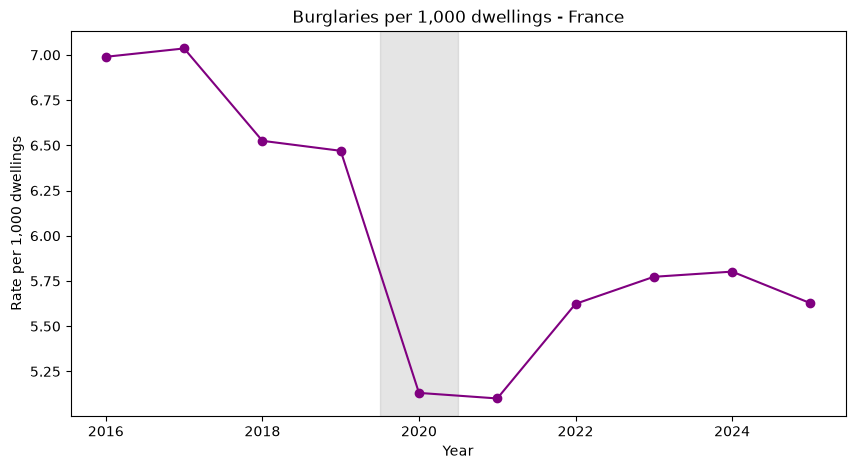

In [20]:
burglary = df[df["indicateur"] == "Cambriolages de logement"]
by_year = burglary.groupby("annee")[["nombre", "denominateur"]].sum()
by_year["taux"] = by_year["nombre"] / by_year["denominateur"] * 1000

plt.figure(figsize=(10,5))
plt.plot(by_year.index, by_year["taux"], marker="o", color="purple")
plt.axvspan(2019.5, 2020.5, color="grey", alpha=0.2)
plt.title("Burglaries per 1,000 dwellings - France")
plt.xlabel("Year")
plt.ylabel("Rate per 1,000 dwellings")
plt.show()

- Question : How did burglaries evolve ? 

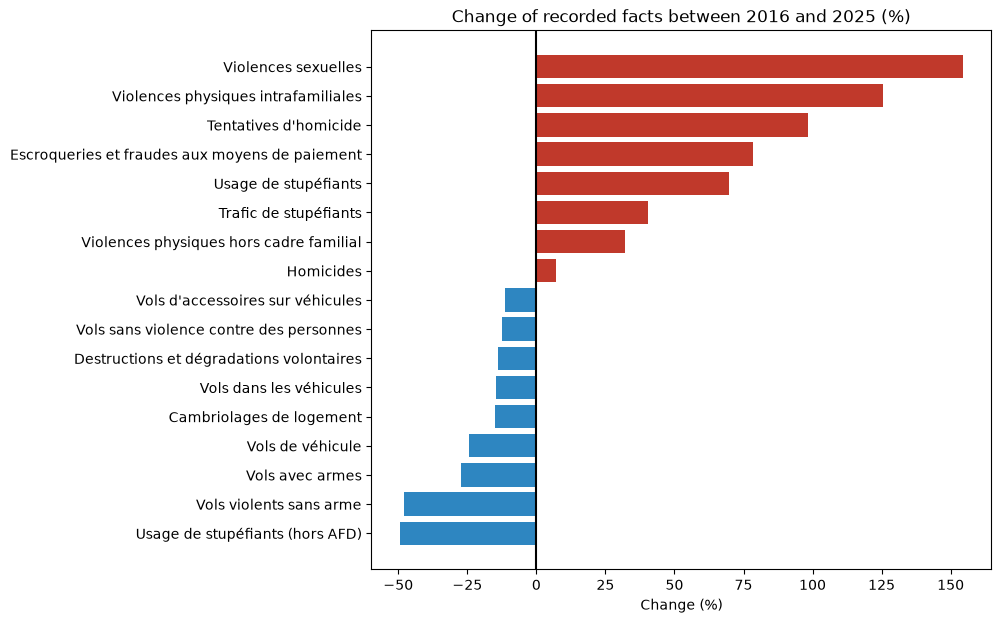

In [ ]:
first = df["annee"].min()
last = df["annee"].max()
evo = df[df["annee"].isin([first, last])].groupby(["indicateur", "annee"])["nombre"].sum().unstack()
evo = evo[evo[first] > 0]  
evo["evolution"] = (evo[last] - evo[first]) / evo[first] * 100
evo = evo.sort_values("evolution")

plt.figure(figsize=(8,7))
colors = ["#c0392b" if x > 0 else "#2e86c1" for x in evo["evolution"]]
plt.barh(evo.index, evo["evolution"], color=colors)
plt.axvline(0, color="black")
plt.title(f"Change of recorded facts between {first} and {last} (%)")
plt.xlabel("Change (%)")
plt.show()

- Question : Which types of crime are increasing ?

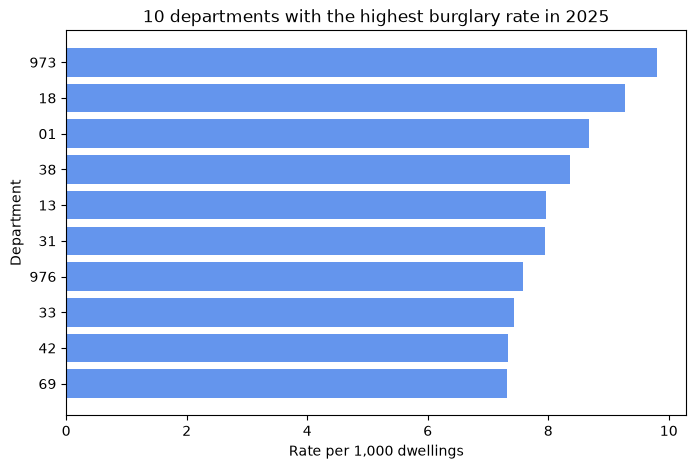

In [27]:
last_year = burglary[burglary["annee"] == last].sort_values("taux_calcule", ascending=False)

plt.figure(figsize=(8,5))
plt.barh(last_year["code_departement"].head(10)[::-1], last_year["taux_calcule"].head(10)[::-1], color="cornflowerblue")
plt.title(f"10 departments with the highest burglary rate in {last}")
plt.xlabel("Rate per 1,000 dwellings")
plt.ylabel("Department")
plt.show()

- Question : Which departments are the most affected ? 

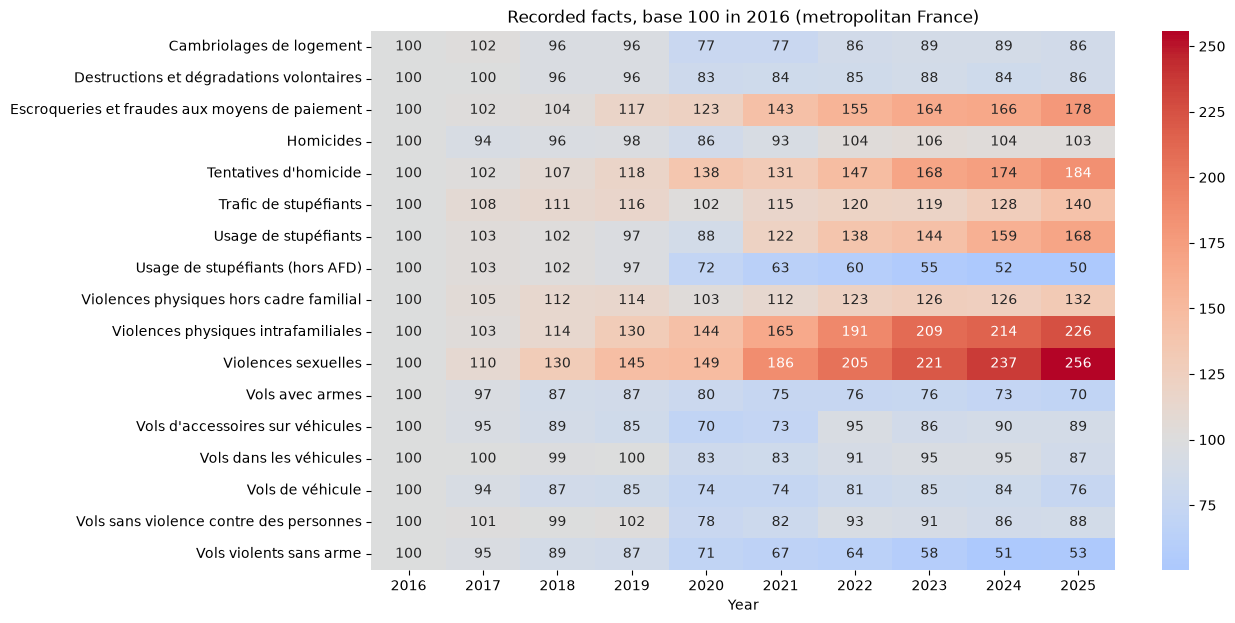

In [36]:
pivot = df[~df["outre_mer"]].pivot_table(index="indicateur", columns="annee", values="nombre", aggfunc="sum")
pivot = pivot[pivot[first] > 0]  
pivot = pivot.div(pivot[first], axis=0) * 100 

plt.figure(figsize=(12,7))
sns.heatmap(pivot, cmap="coolwarm", center=100, annot=True, fmt=".0f")
plt.title(f"Recorded facts, base 100 in {first} (metropolitan France)")
plt.xlabel("Year")
plt.ylabel("")
plt.show()
pivot = pivot.div(pivot[first], axis=0) * 100 


- Question : Was 2020 different ? 